In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
from sklearn .model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.metrics import precision_score, recall_score, f1_score

from sklearn.metrics import roc_curve, roc_auc_score

from sklearn.linear_model import LogisticRegression

In [33]:
import os
import pandas as pd

# Notice the space between 'HR_comma_sep' and '(1).csv'
file_path = os.path.join(
    os.path.expanduser("~/Downloads"),
    "iris.csv"
)

# Read the CSV file
df = pd.read_csv(file_path)

# Display the first few rows
df.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [34]:
df.tail()

,sepal.length,sepal.width,petal.length,petal.width,variety
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica
149,5.9,3.0,5.1,1.8,Virginica


In [35]:
df['variety'].value_counts()

variety
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64

In [36]:
df.describe()

,sepal.length,sepal.width,petal.length,petal.width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [37]:
df.isna().sum().fillna(0)

sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
variety         0
dtype: int64

In [38]:
df.corr(numeric_only=True)

,sepal.length,sepal.width,petal.length,petal.width
sepal.length,1.000000,-0.117570,0.871754,0.817941
sepal.width,-0.117570,1.000000,-0.428440,-0.366126
petal.length,0.871754,-0.428440,1.000000,0.962865
petal.width,0.817941,-0.366126,0.962865,1.000000


In [39]:
cro=pd.crosstab(df['sepal.length'],df['sepal.width'],margins=True)

In [40]:
cro

sepal.width,2.0,2.2,2.3,2.4,2.5,2.6,2.7,2.8,2.9,3.0,...,3.5,3.6,3.7,3.8,3.9,4.0,4.1,4.2,4.4,All
sepal.length,,,,,,,,,,,,,,,,,,,,,
4.3,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
4.4,0,0,0,0,0,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,3
4.5,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4.6,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,4
4.7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
4.8,0,0,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,5
4.9,0,0,0,1,1,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,6
5.0,1,0,1,0,0,0,0,0,0,1,...,2,1,0,0,0,0,0,0,0,10
5.1,0,0,0,0,1,0,0,0,0,0,...,2,0,1,3,0,0,0,0,0,9


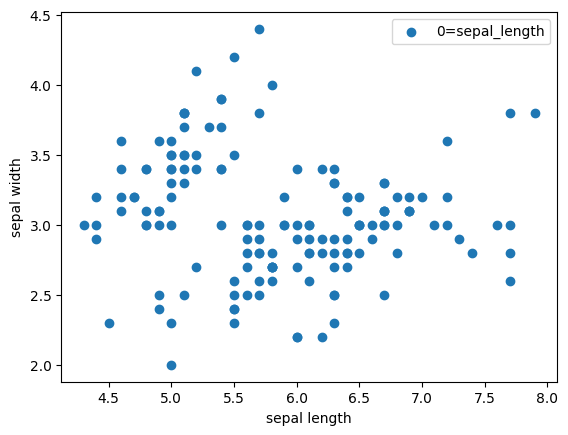

In [41]:
plt.scatter(x=df['sepal.length'],y=df['sepal.width'])
plt.xlabel('sepal length')
plt.ylabel('sepal width')
plt.legend(['0=sepal_length', '1=sepal_width'])


In [12]:
cro=pd.crosstab(df['petal.length'],df['petal.width'],margins=True)

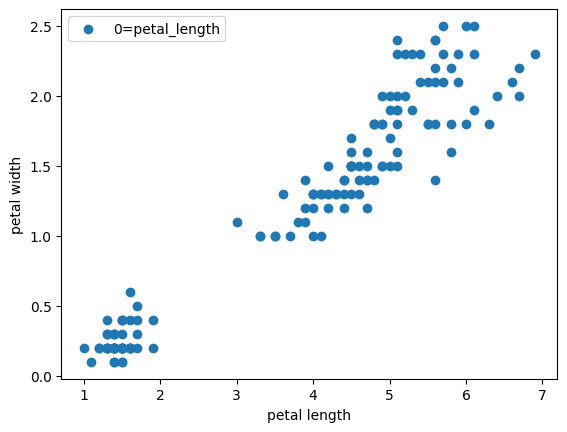

In [13]:
plt.scatter(x=df['petal.length'],y=df['petal.width'])
plt.xlabel('petal length')
plt.ylabel('petal width')
plt.legend(['0=petal_length', '1=petal_width'])

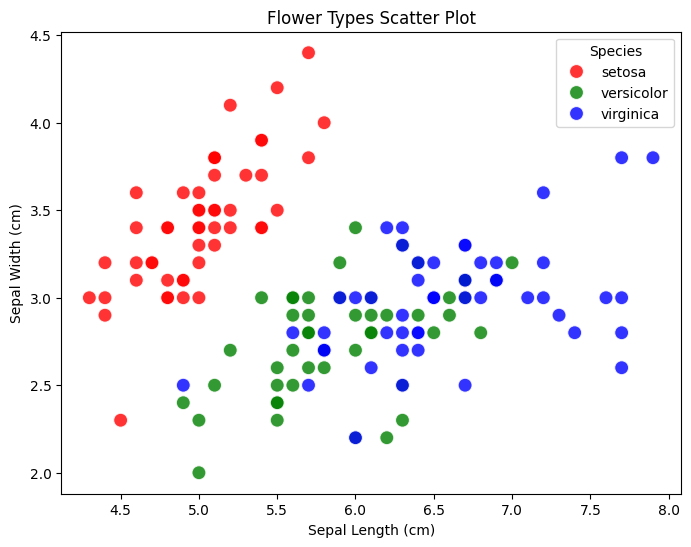

In [42]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris

# 1. Load the Iris dataset into a DataFrame
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['flower_name'] = pd.Series(iris.target).map(
    {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
)

# 2. Define custom colors for each flower
custom_colors = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}

# 3. Create the scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='sepal length (cm)',
    y='sepal width (cm)',
    hue='flower_name',
    palette=custom_colors,
    s=100,  # Size of the dots
    alpha=0.8,
)

# 4. Add titles and labels
plt.title('Flower Types Scatter Plot')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.legend(title='Species')
plt.show()

In [45]:
x_train,x_test,y_train,y_test=train_test_split(df.iloc[:,0:4],df.iloc[:,4],test_size=0.2,random_state=42)

In [47]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),flower_name
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [54]:

from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(
    categories=[['setosa', 'versicolor', 'virginica']]
)

y_train_new = encoder.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

y_test_new = encoder.transform(
    y_test.to_numpy().reshape(-1, 1)
)



In [55]:
y_train_new

array([[0.],
       [0.],
       [1.],
       [0.],
       [0.],
       [2.],
       [1.],
       [0.],
       [0.],
       [0.],
       [2.],
       [1.],
       [1.],
       [0.],
       [0.],
       [1.],
       [2.],
       [2.],
       [1.],
       [2.],
       [1.],
       [2.],
       [1.],
       [0.],
       [2.],
       [1.],
       [0.],
       [0.],
       [0.],
       [1.],
       [2.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [1.],
       [2.],
       [0.],
       [1.],
       [2.],
       [0.],
       [2.],
       [2.],
       [1.],
       [1.],
       [2.],
       [1.],
       [0.],
       [1.],
       [2.],
       [0.],
       [0.],
       [1.],
       [1.],
       [0.],
       [2.],
       [0.],
       [0.],
       [1.],
       [1.],
       [2.],
       [1.],
       [2.],
       [2.],
       [1.],
       [0.],
       [0.],
       [2.],
       [2.],
       [0.],
       [0.],
       [0.],
       [1.],
       [2.],
       [0.],
       [2.],

In [56]:
y_test_new

array([[1.],
       [0.],
       [2.],
       [1.],
       [1.],
       [0.],
       [1.],
       [2.],
       [1.],
       [1.],
       [2.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [2.],
       [1.],
       [1.],
       [2.],
       [0.],
       [2.],
       [0.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [0.],
       [0.]])

In [57]:
x_train




,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
22,4.6,3.6,1.0,0.2
15,5.7,4.4,1.5,0.4
65,6.7,3.1,4.4,1.4
11,4.8,3.4,1.6,0.2
42,4.4,3.2,1.3,0.2
...,...,...,...,...
71,6.1,2.8,4.0,1.3
106,4.9,2.5,4.5,1.7
14,5.8,4.0,1.2,0.2
92,5.8,2.6,4.0,1.2


In [58]:
x_test

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
73,6.1,2.8,4.7,1.2
18,5.7,3.8,1.7,0.3
118,7.7,2.6,6.9,2.3
78,6.0,2.9,4.5,1.5
76,6.8,2.8,4.8,1.4
31,5.4,3.4,1.5,0.4
64,5.6,2.9,3.6,1.3
141,6.9,3.1,5.1,2.3
68,6.2,2.2,4.5,1.5
82,5.8,2.7,3.9,1.2


In [59]:
lgrc=LogisticRegression()
lgrc.fit(x_train,y_train_new)


c:\Users\muham\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [60]:
lgrc.score(x_test,y_test_new)

1.0

In [61]:
lgrc.score(x_train,y_train_new)

0.975

In [62]:
y_predict=lgrc.predict(x_test)

In [63]:
y_predict

array([1., 0., 2., 1., 1., 0., 1., 2., 1., 1., 2., 0., 0., 0., 0., 1., 2.,
       1., 1., 2., 0., 2., 0., 2., 2., 2., 2., 2., 0., 0.])